# Data Sanity Checks

Verification that the loaded NHL data is correct, complete, and trustworthy
**before** building models on it. Re-run this notebook after any data pull.

**Sections**
1. Setup
2. Row counts & per-season coverage
3. Team coverage (home/away balance)
4. Shot coordinate distributions  *(highest-value visual check)*
5. Goals reconcile with final scores  *(highest-value correctness check)*
6. NULL rates on model-critical columns
7. Single known-game deep dive
8. game_events completeness  *(new — full play-by-play)*
9. Event ordering & join-key integrity  *(new)*
10. shot_context coverage & flag plausibility  *(new — rebound/rush)*
11. Blocked-shot attribution check  *(new — known API quirk)*
12. Rink plot smoke test  *(new — viz)*

The division of labor: sections 2–3 confirm the data is *present and complete*,
4–6 confirm it is *internally consistent*, and 7 confirms it *matches external reality*.
Sections 8–11 do the same for the full-event tables that back the rebound/rush
xG features: 8–9 are presence/integrity, 10–11 are consistency. Section 12 is a
visual end-to-end check.

## 1. Setup

In [1]:
import sys
sys.path.insert(0, "..")  # notebook lives in notebooks/, project root is one level up

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.data.db import get_connection, get_shots_for_game

conn = get_connection()
pd.set_option("display.max_columns", None)
print("Connected.")

Connected.


## 2. Row counts & per-season coverage

Confirm every table is populated and the per-season game counts look right
(~1,312 games per full regular season).

In [2]:
tables = ["teams", "players", "schedule", "games", "skater_game_stats",
          "goalie_game_stats", "shot_events", "shifts",
          "game_events", "shot_context"]   # new tables; MISSING until backfill_game_events.py has run

existing = {r[0] for r in conn.execute("SELECT name FROM sqlite_master WHERE type='table'")}
counts = {t: (conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] if t in existing else "MISSING")
          for t in tables}
pd.DataFrame.from_dict(counts, orient="index", columns=["rows"])

,rows
teams,32
players,876
schedule,6560
games,6560
skater_game_stats,236101
goalie_game_stats,26238
shot_events,773259
shifts,4578542
game_events,2060996
shot_context,566545


In [3]:
# Games + shots per season, with shots-per-game derived
season_summary = pd.read_sql('''
    SELECT
        g.season,
        COUNT(DISTINCT g.id)                       AS games,
        COUNT(s.event_id)                          AS shot_events,
        ROUND(COUNT(s.event_id) * 1.0 / COUNT(DISTINCT g.id), 1) AS shots_per_game
    FROM games g
    LEFT JOIN shot_events s ON s.game_id = g.id
    GROUP BY g.season
    ORDER BY g.season
''', conn)
season_summary

,season,games,shot_events,shots_per_game
0,20212022,1312,149412,113.9
1,20222023,1312,153348,116.9
2,20232024,1312,160123,122.0
3,20242025,1312,156622,119.4
4,20252026,1312,153754,117.2


In [4]:
# What's the most recent game in the data? (sanity on date coverage)
latest = conn.execute("SELECT MAX(game_date) FROM games").fetchone()[0]
earliest = conn.execute("SELECT MIN(game_date) FROM games").fetchone()[0]
print(f"Game date range: {earliest}  ->  {latest}")

Game date range: 2021-10-12  ->  2026-04-16


## 3. Team coverage (home/away balance)

Every team should have a roughly equal total number of games, and home games
should be ~50% of each team's total. A team with a lopsided home/away split or a
suspiciously low total points to a parsing or filtering problem.

In [5]:
home = pd.read_sql(
    "SELECT home_team_abbrev AS team, COUNT(*) AS home_games FROM games GROUP BY home_team_abbrev",
    conn).set_index("team")
away = pd.read_sql(
    "SELECT away_team_abbrev AS team, COUNT(*) AS away_games FROM games GROUP BY away_team_abbrev",
    conn).set_index("team")

balance = home.join(away)
balance["total"] = balance.home_games + balance.away_games
balance["home_pct"] = (balance.home_games / balance.total).round(3)
balance = balance.sort_values("total")
print(f"Teams: {len(balance)}")
print(f"Total range: {balance.total.min()} - {balance.total.max()}")
print(f"home_pct range: {balance.home_pct.min():.3f} - {balance.home_pct.max():.3f}")
balance

Teams: 33
Total range: 164 - 410
home_pct range: 0.500 - 0.500


,home_games,away_games,total,home_pct
team,,,,
UTA,82,82,164,0.5
ARI,123,123,246,0.5
BOS,205,205,410,0.5
ANA,205,205,410,0.5
CAR,205,205,410,0.5
CBJ,205,205,410,0.5
CGY,205,205,410,0.5
BUF,205,205,410,0.5
COL,205,205,410,0.5


## 4. Shot coordinate distributions  *(highest-value visual check)*

The single most informative check. Load every shot with coordinates and look at
where they land.

**What healthy data looks like:** two symmetric clusters (the NHL records shots
from both ends, so raw x spans roughly -100 to +100), density concentrated in
front of each net, thinning toward the blue lines, near-empty at center ice.

**Red flags:**
- A spike at exactly (0, 0) -> missing coords stored as zero instead of NULL
- Strong left/right asymmetry -> home/away coordinate-flip bug
- Points outside +/-100 (x) or +/-42.5 (y) -> units / scaling problem

In [6]:
shots = pd.read_sql('''
    SELECT x_coord, y_coord, event_type, team_id
    FROM shot_events
    WHERE x_coord IS NOT NULL AND y_coord IS NOT NULL
''', conn)

print(f"Shots with coordinates: {len(shots):,}")
print(f"x range: [{shots.x_coord.min():.0f}, {shots.x_coord.max():.0f}]")
print(f"y range: [{shots.y_coord.min():.0f}, {shots.y_coord.max():.0f}]")

# Check for the (0,0) spike specifically
at_origin = ((shots.x_coord == 0) & (shots.y_coord == 0)).sum()
print(f"Shots at exactly (0, 0): {at_origin:,}  "
      f"({at_origin / len(shots):.2%}) -- should be near zero")

Shots with coordinates: 773,259
x range: [-99, 99]
y range: [-42, 42]
Shots at exactly (0, 0): 19  (0.00%) -- should be near zero


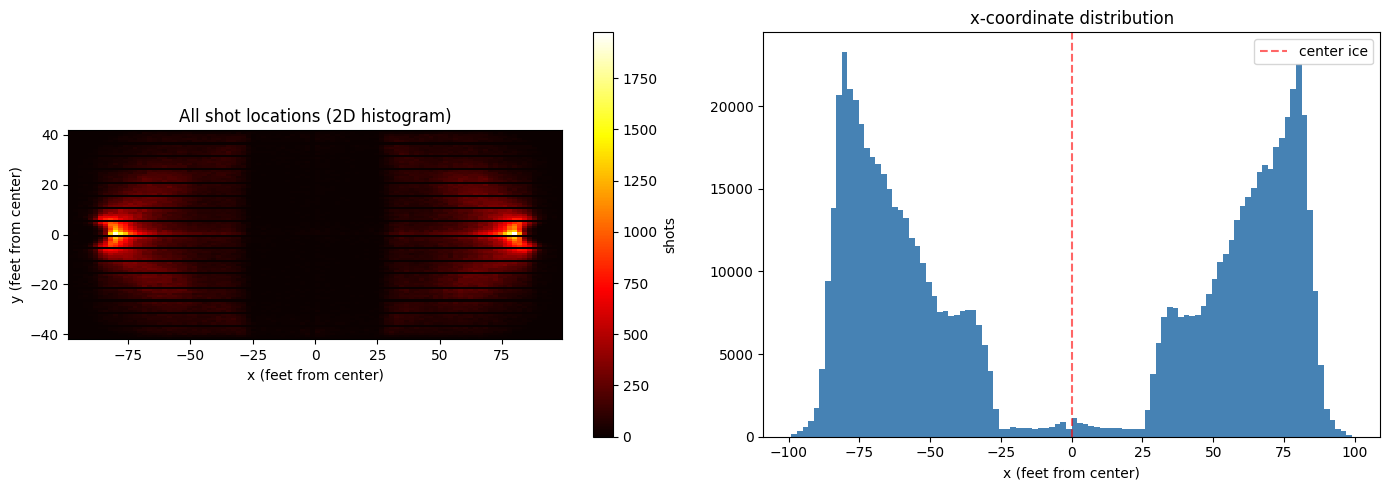

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 2D histogram of all shot locations
h = axes[0].hist2d(shots.x_coord, shots.y_coord, bins=100, cmap="hot")
axes[0].set_title("All shot locations (2D histogram)")
axes[0].set_xlabel("x (feet from center)")
axes[0].set_ylabel("y (feet from center)")
axes[0].set_aspect("equal")
fig.colorbar(h[3], ax=axes[0], label="shots")

# Marginal x distribution (should be roughly bimodal & symmetric)
axes[1].hist(shots.x_coord, bins=100, color="steelblue")
axes[1].axvline(0, color="red", linestyle="--", alpha=0.6, label="center ice")
axes[1].set_title("x-coordinate distribution")
axes[1].set_xlabel("x (feet from center)")
axes[1].legend()

plt.tight_layout()
plt.show()

## 5. Goals reconcile with final scores  *(highest-value correctness check)*

For a sample of games, count `goal` events in `shot_events` and compare to the
official `home_score` / `away_score` in the `games` table. If these disagree,
something is wrong with how goals are recorded or attributed -- which would
poison both the xG model (mislabeled outcomes) and the game model (wrong counts).

**Expected quirk:** shootout-decided games. The official score includes one
shootout-winner goal that does *not* appear as a normal `goal` event in
play-by-play. So expect a small number of off-by-one mismatches that cluster on
one-goal-margin games. That's the shootout signature, not a bug -- but this check
is how you learn to recognize it.

In [8]:
# Count goal events per (game, team)
goal_events = pd.read_sql('''
    SELECT game_id, team_id, COUNT(*) AS goals_in_events
    FROM shot_events
    WHERE event_type = 'goal'
    GROUP BY game_id, team_id
''', conn)

# Official scores + team ids, joined from games + schedule
games = pd.read_sql('''
    SELECT g.id AS game_id, g.home_score, g.away_score,
           g.home_team_abbrev, g.away_team_abbrev,
           sc.home_team_id, sc.away_team_id
    FROM games g
    JOIN schedule sc ON sc.game_id = g.id
''', conn)

# Build quick lookup: (game_id, team_id) -> goal count
goal_lookup = {(r.game_id, r.team_id): r.goals_in_events
               for r in goal_events.itertuples()}

def event_goals(game_id, team_id):
    return goal_lookup.get((game_id, team_id), 0)

# Sample for speed (vectorize later if it looks clean)
sample = games.sample(min(300, len(games)), random_state=42).copy()
sample["event_home_goals"] = [event_goals(r.game_id, r.home_team_id) for r in sample.itertuples()]
sample["event_away_goals"] = [event_goals(r.game_id, r.away_team_id) for r in sample.itertuples()]
sample["home_match"] = sample.home_score == sample.event_home_goals
sample["away_match"] = sample.away_score == sample.event_away_goals
sample["full_match"] = sample.home_match & sample.away_match

mismatch_rate = 1 - sample.full_match.mean()
print(f"Sampled games: {len(sample)}")
print(f"Full-match rate: {sample.full_match.mean():.1%}")
print(f"Mismatch rate:   {mismatch_rate:.1%}")

Sampled games: 300
Full-match rate: 96.7%
Mismatch rate:   3.3%


In [9]:
# Inspect mismatches. Margin == 1 on the official score is the shootout signature.
mism = sample[~sample.full_match].copy()
mism["off_by"] = (
    (mism.home_score - mism.event_home_goals).abs()
    + (mism.away_score - mism.event_away_goals).abs()
)
mism["score_margin"] = (mism.home_score - mism.away_score).abs()
print(f"Mismatches: {len(mism)}")
if len(mism):
    print(f"  ...of which off-by-exactly-1: {(mism.off_by == 1).sum()} "
          f"(likely shootouts)")
mism[["game_id", "home_team_abbrev", "home_score", "event_home_goals",
      "away_team_abbrev", "away_score", "event_away_goals",
      "off_by", "score_margin"]].head(20)

Mismatches: 10
  ...of which off-by-exactly-1: 2 (likely shootouts)


,game_id,home_team_abbrev,home_score,event_home_goals,away_team_abbrev,away_score,event_away_goals,off_by,score_margin
6050,2025020803,CHI,1,3,TBL,2,4,4,1
233,2021020234,NJD,2,3,OTT,3,4,2,1
4783,2024020848,PIT,2,4,NJD,3,5,4,1
5400,2025020153,FLA,2,3,ANA,3,4,2,1
3352,2023020729,LAK,3,3,SJS,4,5,1,1
2883,2023020260,CGY,4,5,NYI,5,6,2,1
4160,2024020225,FLA,4,5,PHI,3,4,2,1
604,2021020605,DAL,6,7,FLA,5,5,1,1
4649,2024020714,NSH,3,5,CHI,2,3,3,1
5899,2025020652,WSH,2,4,CHI,3,5,4,1


In [10]:
# How many events live in period 5 (shootout) and what types are they?
print("Events by period:")
print(pd.read_sql("""
    SELECT period, event_type, COUNT(*) AS n
    FROM shot_events
    WHERE period >= 4
    GROUP BY period, event_type
    ORDER BY period, n DESC
""", conn).to_string(index=False))

# How many 'goal' events are in the shootout specifically?
so_goals = conn.execute(
    "SELECT COUNT(*) FROM shot_events WHERE period = 5 AND event_type = 'goal'"
).fetchone()[0]
total_goals = conn.execute(
    "SELECT COUNT(*) FROM shot_events WHERE event_type = 'goal'"
).fetchone()[0]
print(f"\nShootout 'goals': {so_goals:,} of {total_goals:,} total "
      f"({so_goals/total_goals:.1%})")

# Re-run the reconciliation EXCLUDING period 5, see if mismatch drops
goal_events_no_so = pd.read_sql("""
    SELECT game_id, team_id, COUNT(*) AS goals_in_events
    FROM shot_events
    WHERE event_type = 'goal' AND period < 5
    GROUP BY game_id, team_id
""", conn)
print(f"\nRe-run reconciliation with period < 5 filter to confirm match rate improves.")

Events by period:
 period   event_type    n
      4 shot-on-goal 4596
      4  missed-shot 1937
      4 blocked-shot 1521
      4         goal  984
      5 shot-on-goal 1673
      5         goal 1065
      5  missed-shot  566

Shootout 'goals': 1,065 of 41,536 total (2.6%)

Re-run reconciliation with period < 5 filter to confirm match rate improves.


In [11]:
# Reconciliation, this time excluding shootout (period 5) goal events
goal_events_clean = pd.read_sql('''
    SELECT game_id, team_id, COUNT(*) AS goals_in_events
    FROM shot_events
    WHERE event_type = 'goal' AND period < 5
    GROUP BY game_id, team_id
''', conn)

goal_lookup_clean = {(r.game_id, r.team_id): r.goals_in_events
                     for r in goal_events_clean.itertuples()}

def event_goals_clean(game_id, team_id):
    return goal_lookup_clean.get((game_id, team_id), 0)

# Reuse the same 300-game sample for an apples-to-apples comparison
sample["event_home_goals_clean"] = [
    event_goals_clean(r.game_id, r.home_team_id) for r in sample.itertuples()
]
sample["event_away_goals_clean"] = [
    event_goals_clean(r.game_id, r.away_team_id) for r in sample.itertuples()
]
sample["full_match_clean"] = (
    (sample.home_score == sample.event_home_goals_clean)
    & (sample.away_score == sample.event_away_goals_clean)
)

print(f"Match rate WITH shootout goals:    {sample.full_match.mean():.1%}")
print(f"Match rate WITHOUT shootout goals: {sample.full_match_clean.mean():.1%}")

# Inspect any remaining mismatches — should be off-by-1 shootout-winner credits
resid = sample[~sample.full_match_clean].copy()
resid["off_by"] = (
    (resid.home_score - resid.event_home_goals_clean).abs()
    + (resid.away_score - resid.event_away_goals_clean).abs()
)
print(f"\nRemaining mismatches: {len(resid)}")
if len(resid):
    print(f"  off-by-exactly-1: {(resid.off_by == 1).sum()} (expected shootout-winner credit)")
    print(f"  off-by-more-than-1: {(resid.off_by > 1).sum()} (investigate if nonzero)")

Match rate WITH shootout goals:    96.7%
Match rate WITHOUT shootout goals: 94.7%

Remaining mismatches: 16
  off-by-exactly-1: 16 (expected shootout-winner credit)
  off-by-more-than-1: 0 (investigate if nonzero)


## 6. NULL rates on model-critical columns

How much of the data is actually usable for the xG model. Some NULL coordinate
rate is expected and legitimate -- blocked shots have no recordable shot location.
You want to *know* the number so you can decide how to filter, and so a 40% rate
(a real problem) doesn't hide behind an assumed 15% (just blocked shots).

In [12]:
null_checks = pd.read_sql('''
    SELECT
        COUNT(*) AS total,
        SUM(CASE WHEN x_coord IS NULL THEN 1 ELSE 0 END)            AS null_x,
        SUM(CASE WHEN y_coord IS NULL THEN 1 ELSE 0 END)            AS null_y,
        SUM(CASE WHEN shot_type IS NULL THEN 1 ELSE 0 END)          AS null_shot_type,
        SUM(CASE WHEN shooting_player_id IS NULL THEN 1 ELSE 0 END) AS null_shooter
    FROM shot_events
''', conn)

total = null_checks.total.iloc[0]
print(f"Total shot events: {total:,}\n")
for col in ["null_x", "null_y", "null_shot_type", "null_shooter"]:
    n = null_checks[col].iloc[0]
    print(f"  {col:18s}: {n:>8,}  ({n/total:.1%})")

# Breakdown by event_type: blocked shots are the expected source of NULL coords
print("\nNULL-coordinate rate by event_type:")
by_type = pd.read_sql('''
    SELECT event_type,
           COUNT(*) AS n,
           SUM(CASE WHEN x_coord IS NULL THEN 1 ELSE 0 END) AS null_coords
    FROM shot_events
    GROUP BY event_type
    ORDER BY n DESC
''', conn)
by_type["null_pct"] = (by_type.null_coords / by_type.n).round(3)
print(by_type.to_string(index=False))

Total shot events: 773,259

  null_x            :        0  (0.0%)
  null_y            :        0  (0.0%)
  null_shot_type    :  203,502  (26.3%)
  null_shooter      :        0  (0.0%)

NULL-coordinate rate by event_type:
  event_type      n  null_coords  null_pct
shot-on-goal 352959            0       0.0
blocked-shot 203410            0       0.0
 missed-shot 175354            0       0.0
        goal  41536            0       0.0


In [13]:
# 6b. NULL shooter/shot_type broken out by event_type.
# Aggregate NULL rates hide attribution bugs. Blocked shots legitimately lack
# shot_type. If 'goal' shows a high null_shooter rate, the parser is reading
# shootingPlayerId only and missing scoringPlayerId -> run
# scripts/fix_goal_shooters.py and patch parse_shot_events in nhl_api.py.
attrib = pd.read_sql('''
    SELECT event_type,
           COUNT(*) AS n,
           SUM(CASE WHEN shooting_player_id IS NULL THEN 1 ELSE 0 END) AS null_shooter,
           SUM(CASE WHEN shot_type IS NULL THEN 1 ELSE 0 END)          AS null_shot_type
    FROM shot_events GROUP BY event_type ORDER BY n DESC
''', conn)
attrib["null_shooter_pct"] = (attrib.null_shooter / attrib.n).round(3)
attrib["null_shot_type_pct"] = (attrib.null_shot_type / attrib.n).round(3)
print(attrib.to_string(index=False))

goal_nulls = attrib.loc[attrib.event_type == "goal", "null_shooter"].sum()
print(f"\nGoals with no shooter: {goal_nulls:,}  (expect 0 after the fix)")

  event_type      n  null_shooter  null_shot_type  null_shooter_pct  null_shot_type_pct
shot-on-goal 352959             0               0               0.0               0.000
blocked-shot 203410             0          203410               0.0               1.000
 missed-shot 175354             0               0               0.0               0.000
        goal  41536             0              92               0.0               0.002

Goals with no shooter: 0  (expect 0 after the fix)


## 7. Single known-game deep dive

Pick one game you can verify against an external source (NHL.com, Natural Stat
Trick). The human-in-the-loop check that catches things automated checks miss:
do the goals happen at plausible times, does the shot mix look like real hockey,
do the totals match what actually happened.

In [14]:
game_id = 2025020034  # DAL @ COL -- change to any game you want to verify

# Use the real loader from db.py
shot_objs = get_shots_for_game(conn, game_id)
print(f"Loaded {len(shot_objs)} shot events for game {game_id}\n")

ev = pd.DataFrame([{
    "period": s.period, "time": s.time_in_period,
    "event_type": s.event_type, "team_id": s.team_id,
    "shot_type": s.shot_type, "x": s.x_coord, "y": s.y_coord,
} for s in shot_objs])

print("Event type counts:")
print(ev.event_type.value_counts().to_string())
print("\nGoals:")
print(ev[ev.event_type == "goal"][["period", "time", "team_id", "shot_type"]].to_string(index=False))

Loaded 131 shot events for game 2025020034

Event type counts:
event_type
shot-on-goal    56
blocked-shot    34
missed-shot     30
goal            11

Goals:
 period  time  team_id shot_type
      1 18:51       25      slap
      2 03:54       21     wrist
      2 10:07       21      snap
      2 15:22       25     wrist
      2 18:25       25    tip-in
      3 00:34       21      snap
      3 01:58       25     wrist
      3 10:46       21      snap
      5 00:00       25     wrist
      5 00:00       25     wrist
      5 00:00       21  backhand


In [15]:
# Cross-check against the official score for this game
row = conn.execute('''
    SELECT home_team_abbrev, away_team_abbrev, home_score, away_score
    FROM games WHERE id = ?
''', (game_id,)).fetchone()
if row:
    print(f"Official: {row[1]} {row[3]} @ {row[0]} {row[2]}")
    print(f"Goal events in data: {(ev.event_type == 'goal').sum()}")
else:
    print(f"Game {game_id} not found in games table.")

Official: DAL 5 @ COL 4
Goal events in data: 11


## 8. game_events completeness  *(new — full play-by-play)*

`game_events` stores **every** event type (faceoffs, hits, takeaways, ...), not just
shots — it's the raw record that backs the rebound/rush derivation. Three checks:
every game with shot data also has full events; per-game event volume is plausible
(~300–400 events/game); and the shot-type subset of `game_events` is a **superset**
of `shot_events` (the shot_events parser skips rows without coordinates,
the game_events parser keeps everything).

In [16]:
ge_games = conn.execute("SELECT COUNT(DISTINCT game_id) FROM game_events").fetchone()[0]
se_games = conn.execute("SELECT COUNT(DISTINCT game_id) FROM shot_events").fetchone()[0]
missing = conn.execute('''
    SELECT COUNT(*) FROM (
        SELECT DISTINCT game_id FROM shot_events
        WHERE game_id NOT IN (SELECT DISTINCT game_id FROM game_events)
    )
''').fetchone()[0]

print(f"Games with shot_events:  {se_games:,}")
print(f"Games with game_events:  {ge_games:,}")
print(f"Games missing full events: {missing:,}  (expect 0 — re-run scripts/backfill_game_events.py if not)")

# Per-game event volume. NHL games typically log ~300-400 events.
per_game = pd.read_sql(
    "SELECT game_id, COUNT(*) AS n_events FROM game_events GROUP BY game_id", conn)
print(f"\nEvents per game: median {per_game.n_events.median():.0f}, "
      f"min {per_game.n_events.min()}, max {per_game.n_events.max()}")
print("Suspiciously thin games (< 150 events) — investigate if nonzero:",
      (per_game.n_events < 150).sum())

Games with shot_events:  6,560
Games with game_events:  6,560
Games missing full events: 0  (expect 0 — re-run scripts/backfill_game_events.py if not)

Events per game: median 313, min 218, max 437
Suspiciously thin games (< 150 events) — investigate if nonzero: 0


In [17]:
# Event-type inventory + shot-subset comparison against shot_events
inventory = pd.read_sql('''
    SELECT event_type, COUNT(*) AS n FROM game_events
    GROUP BY event_type ORDER BY n DESC
''', conn)
print(inventory.to_string(index=False))

shot_types = ("shot-on-goal", "goal", "missed-shot", "blocked-shot")
ge_shots = conn.execute(
    f"SELECT COUNT(*) FROM game_events WHERE event_type IN {shot_types}").fetchone()[0]
se_shots = conn.execute("SELECT COUNT(*) FROM shot_events").fetchone()[0]
print(f"\nShot-type rows in game_events: {ge_shots:,}")
print(f"Rows in shot_events:           {se_shots:,}")
print(f"Difference: {ge_shots - se_shots:,} (shots the shot_events parser skipped "
      f"for missing coordinates — should be small and NEVER negative)")

         event_type      n
            faceoff 370890
       shot-on-goal 352959
                hit 288862
           stoppage 288079
       blocked-shot 203410
        missed-shot 175354
           giveaway 146132
           takeaway  81061
            penalty  48470
               goal  41536
       period-start  21624
         period-end  21614
    delayed-penalty  13907
           game-end   6560
  shootout-complete    476
failed-shot-attempt     62

Shot-type rows in game_events: 773,259
Rows in shot_events:           773,259
Difference: 0 (shots the shot_events parser skipped for missing coordinates — should be small and NEVER negative)


## 9. Event ordering & join-key integrity  *(new)*

Two structural facts the derivation depends on:
- **Join key.** `shot_context` joins to `shot_events` on `(game_id, event_id)` —
  every shot row must find its match in `game_events`.
- **Chronology.** The API's `eventId` is **not** in play order; `sort_order` is.
  `game_seconds` must be non-decreasing when walked in `sort_order` — if this
  fails, every rebound/rush flag is suspect.

In [18]:
# 9a. Join coverage: every shot_events row must exist in game_events
unmatched = conn.execute('''
    SELECT COUNT(*) FROM shot_events se
    LEFT JOIN game_events ge
           ON ge.game_id = se.game_id AND ge.event_id = se.event_id
    WHERE ge.event_id IS NULL
''').fetchone()[0]
print(f"shot_events rows with no game_events match: {unmatched:,}  (expect 0)")

shot_events rows with no game_events match: 0  (expect 0)


In [19]:
# 9b. Chronology: game_seconds non-decreasing along sort_order (sampled games),
# and how often eventId order disagrees with sort_order (why we never sort by it).
rng = np.random.default_rng(42)
all_ids = [r[0] for r in conn.execute("SELECT DISTINCT game_id FROM game_events")]
sample_ids = rng.choice(all_ids, size=min(200, len(all_ids)), replace=False)

non_monotonic, id_order_differs = 0, 0
for gid in sample_ids:
    g = pd.read_sql('''
        SELECT event_id, sort_order, game_seconds FROM game_events
        WHERE game_id = ? ORDER BY sort_order
    ''', conn, params=(int(gid),))
    if (g.game_seconds.diff().dropna() < 0).any():
        non_monotonic += 1
    if not g.event_id.is_monotonic_increasing:
        id_order_differs += 1

print(f"Sampled games: {len(sample_ids)}")
print(f"Games where time runs backwards along sort_order: {non_monotonic}  (expect 0)")
print(f"Games where eventId order != sort_order: {id_order_differs} "
      f"({id_order_differs/len(sample_ids):.0%}) — any nonzero count is the reason "
      f"the derivation sorts by sort_order, never eventId")

Sampled games: 200
Games where time runs backwards along sort_order: 0  (expect 0)
Games where eventId order != sort_order: 200 (100%) — any nonzero count is the reason the derivation sorts by sort_order, never eventId


## 10. shot_context coverage & flag plausibility  *(new — rebound/rush)*

Coverage contract: one `shot_context` row per **unblocked, period ≤ 4** shot in
`game_events`. Plausibility: **rebounds ~8–13%** of unblocked shots (sensitive to
the window: NST uses 3s, MoneyPuck 2s). **Rush rates land in the mid single
digits** with this event-sparse definition — most shots have no recorded event
within 4 seconds behind them — so validate rush against NST's per-game rush
attempt counts rather than a fixed band.

The teeth of this section is the *signal check*: rebound and rush shots should
convert to goals at a visibly higher rate than other shots — that's the entire
reason they're xG features. If conversion is flat, the flags are mislabeled
even if the rates look right.

In [20]:
# 10a. Coverage both directions
eligible = conn.execute('''
    SELECT COUNT(*) FROM shot_events
    WHERE period <= 4 AND event_type IN ('shot-on-goal','goal','missed-shot')
''').fetchone()[0]
ctx_rows = conn.execute("SELECT COUNT(*) FROM shot_context").fetchone()[0]

no_ctx = conn.execute('''
    SELECT COUNT(*) FROM shot_events se
    LEFT JOIN shot_context sc
           ON sc.game_id = se.game_id AND sc.event_id = se.event_id
    WHERE se.period <= 4
      AND se.event_type IN ('shot-on-goal','goal','missed-shot')
      AND sc.event_id IS NULL
''').fetchone()[0]

print(f"Eligible shots in shot_events: {eligible:,}")
print(f"Rows in shot_context:          {ctx_rows:,}")
print(f"Eligible shots WITHOUT context: {no_ctx:,}  (expect 0 — run build_shot_context if not)")
print(f"\nContext rows exceeding eligible: {max(0, ctx_rows - eligible):,} "
      f"(expected & fine: context derives from game_events, which also keeps "
      f"the few shots that shot_events skipped for missing coordinates)")

Eligible shots in shot_events: 566,545
Rows in shot_context:          566,545
Eligible shots WITHOUT context: 0  (expect 0 — run build_shot_context if not)

Context rows exceeding eligible: 0 (expected & fine: context derives from game_events, which also keeps the few shots that shot_events skipped for missing coordinates)


In [21]:
# 10b. Flag rates + goal-conversion signal
flags = pd.read_sql('''
    SELECT sc.is_rebound, sc.is_rush, se.event_type
    FROM shot_context sc
    JOIN shot_events se
      ON se.game_id = sc.game_id AND se.event_id = sc.event_id
''', conn)
flags["is_goal"] = (flags.event_type == "goal").astype(int)

reb, rush = flags.is_rebound.mean(), flags.is_rush.mean()
print(f"Unblocked shots with context: {len(flags):,}")
print(f"Rebound rate: {reb:.1%}   (plausible ~8-13%, window-dependent)")
print(f"Rush rate:    {rush:.1%}   (mid single digits expected; validate vs NST per-game counts)")

print("\nGoal conversion by flag (the signal check):")
for col in ["is_rebound", "is_rush"]:
    on  = flags.loc[flags[col] == 1, "is_goal"].mean()
    off = flags.loc[flags[col] == 0, "is_goal"].mean()
    print(f"  {col:10s}: flagged {on:.1%} vs unflagged {off:.1%} "
          f"({'OK — flagged converts higher' if on > off else 'INVESTIGATE — no lift'})")

Unblocked shots with context: 566,545
Rebound rate: 9.4%   (plausible ~8-13%, window-dependent)
Rush rate:    2.7%   (mid single digits expected; validate vs NST per-game counts)

Goal conversion by flag (the signal check):
  is_rebound: flagged 12.4% vs unflagged 6.6% (OK — flagged converts higher)
  is_rush   : flagged 7.4% vs unflagged 7.1% (OK — flagged converts higher)


In [22]:
# 10c. What precedes flagged shots? Face validity on the derivation inputs.
# Rebounds should follow shot attempts; rush shots should follow N/D-zone
# possession-change or transition events (takeaway, giveaway, hit, missed-shot...).
ctx = pd.read_sql("SELECT is_rebound, is_rush, last_event_type FROM shot_context", conn)

print("Last event before REBOUND shots (top 6):")
print(ctx[ctx.is_rebound == 1].last_event_type.value_counts(normalize=True)
      .head(6).round(3).to_string())
print("\nLast event before RUSH shots (top 6):")
print(ctx[ctx.is_rush == 1].last_event_type.value_counts(normalize=True)
      .head(6).round(3).to_string())

Last event before REBOUND shots (top 6):
last_event_type
shot-on-goal       0.583
blocked-shot       0.233
missed-shot        0.168
hit                0.007
giveaway           0.005
delayed-penalty    0.002

Last event before RUSH shots (top 6):
last_event_type
hit             0.357
giveaway        0.241
takeaway        0.232
blocked-shot    0.103
shot-on-goal    0.044
missed-shot     0.022


In [23]:
# 10d. Rush conversion split by precursor type.
# Possession-change precursors (takeaway/giveaway) should convert highest;
# if blocked-shot-preceded rush flags sit at the unflagged baseline, that
# precursor group is noise worth excluding from the xG feature.
rush_conv = pd.read_sql('''
    SELECT sc.last_event_type,
           COUNT(*) AS n,
           AVG(CASE WHEN se.event_type = 'goal' THEN 1.0 ELSE 0.0 END) AS goal_rate
    FROM shot_context sc
    JOIN shot_events se
      ON se.game_id = sc.game_id AND se.event_id = sc.event_id
    WHERE sc.is_rush = 1
    GROUP BY sc.last_event_type
    HAVING n >= 200
    ORDER BY goal_rate DESC
''', conn)
baseline = flags.loc[flags.is_rush == 0, "is_goal"].mean()
rush_conv["goal_rate"] = rush_conv.goal_rate.round(3)
print(f"Non-rush baseline conversion: {baseline:.1%}\n")
print(rush_conv.to_string(index=False))

Non-rush baseline conversion: 7.1%

last_event_type    n  goal_rate
   blocked-shot 1607      0.111
       takeaway 3617      0.101
       giveaway 3751      0.090
    missed-shot  346      0.084
            hit 5557      0.040
   shot-on-goal  683      0.037


## 11. Blocked-shot attribution — what the API sends  *(reference only)*

**This table does NOT determine ownership.** It records the zone codes the API
attaches to `blocked-shot` events. Blocks are recorded from the defending frame
(~96% 'D') regardless of which team owns the event, so the zone code cannot tell
you whether `eventOwnerTeamId` is the shooter or the blocker.

The decisive test is `scripts/check_block_attribution.py`, which compares each
blocked shot's `shooting_player_id`'s team against the stored `team_id`. Run it
whenever you suspect the attribution has changed, set
`blocked_shots_owned_by_blocker` in `src/processing/shot_context.py` to match,
then run `scripts/rebuild_shot_context.py`.

Keep this cell as a record of the raw API behaviour — a shift in the zone mix is
a hint that something upstream changed and the script is worth re-running.

In [24]:
blocked_zones = pd.read_sql('''
    SELECT zone_code, COUNT(*) AS n
    FROM game_events WHERE event_type = 'blocked-shot'
    GROUP BY zone_code ORDER BY n DESC
''', conn)
total_blocked = blocked_zones.n.sum()
blocked_zones["pct"] = (blocked_zones.n / total_blocked).round(3)
print(blocked_zones.to_string(index=False))

print("\nZone code is recorded from the defending frame and does NOT identify "
      "the event owner.\nRun scripts/check_block_attribution.py for the verdict.")

zone_code      n   pct
        D 195759 0.962
        O   7312 0.036
        N    339 0.002

Zone code is recorded from the defending frame and does NOT identify the event owner.
Run scripts/check_block_attribution.py for the verdict.


## 12. Rink plot smoke test  *(new — viz)*

End-to-end visual check on the same deep-dive game as section 7: rink renders,
both teams' shots cluster in their offensive zones (side normalization), goals
are annotated, and rebound/rush rings appear (they come from the
`shot_context` join, so empty rings here means section 10 failed).

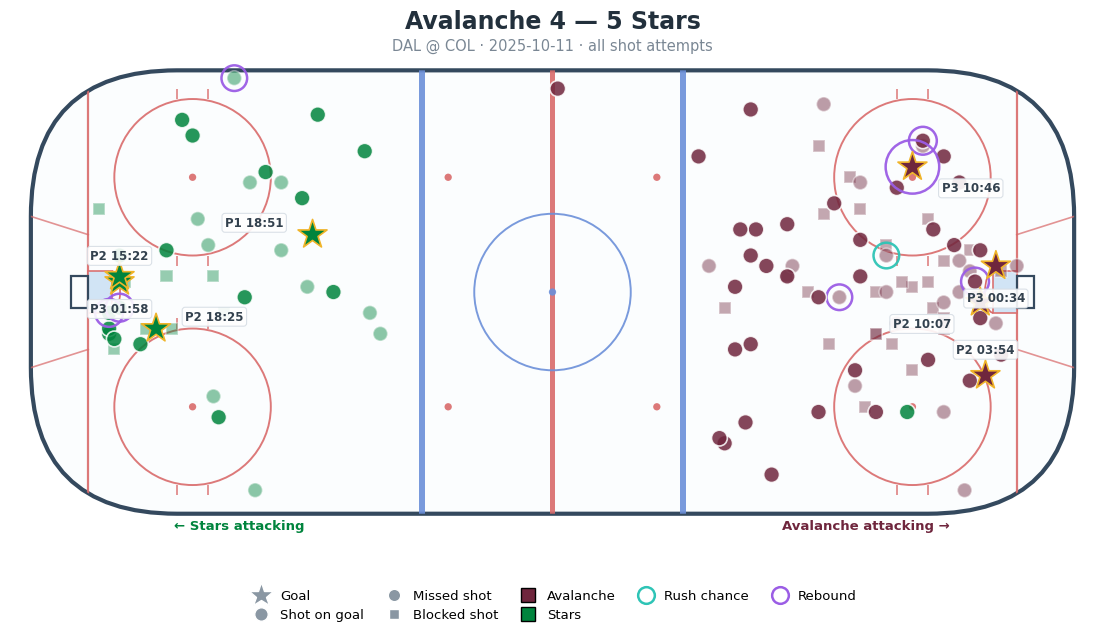

In [25]:
from src.viz.rink_plot import plot_game

plot_game(conn, game_id)   # reuses the section 7 game_id
plt.show()

---
*Re-run top to bottom after any data pull. If sections 4 and 5 pass cleanly, the
data is trustworthy enough to build the xG model on. If sections 9–11 also pass,
the rebound/rush flags are trustworthy enough to USE as xG features — section 10's
conversion lift is the one to watch.*

## 13. Strength state (`situation_code`)  *(xG feature check)*

`situation_code` is a 4-char string: away goalie, away skaters, home skaters,
home goalie. So `1551` = 5v5, `1451` = home power play, `0651` = away goalie
pulled. It is the last unvalidated Phase 2 feature.

Healthy output: no NULLs, 5v5 around 75-80% of shots, and near-symmetric
home/away pairs (1451/1541, 0651/1560, 1351/1531). Asymmetry beyond ~10% suggests
a parsing problem — though home PP slightly outnumbering away PP is real, since
home teams draw more penalties.

For Phase 2, decode this into shooter-relative features (skater differential,
total skaters, empty-net flag) rather than feeding the raw code to LightGBM, and
exclude empty-net shots from xG training.

In [26]:
sit = pd.read_sql('''
    SELECT situation_code, COUNT(*) AS n
    FROM game_events
    WHERE event_type IN ('shot-on-goal','goal','missed-shot')
      AND period <= 4
    GROUP BY situation_code ORDER BY n DESC
''', conn)
total = sit.n.sum()
sit["pct"] = (sit.n / total).round(4)
print(f"NULL/blank rate: {sit[sit.situation_code.isna()].n.sum()/total:.2%}")
print(sit.head(12).to_string(index=False))

NULL/blank rate: 0.00%
situation_code      n    pct
          1551 443925 0.7836
          1451  46630 0.0823
          1541  42315 0.0747
          0651   7525 0.0133
          1560   7308 0.0129
          1441   6245 0.0110
          1331   6198 0.0109
          1351   1347 0.0024
          1531   1121 0.0020
          1341    926 0.0016
          1460    855 0.0015
          0641    843 0.0015


In [27]:
conn.close()
print("Done.")

Done.
